In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../content/reddit_preprocessing.csv")

In [4]:
df

,detail_text,label
0,"u.s. budget fight looms, republican flip fisca...",0
1,u.s. military accept transgender recruit monda...,0
2,senior u.s. republican senator let mr. mueller...,0
3,fbi russia probe helped australian diplomat ti...,0
4,trump want postal service charge much amazon s...,0
...,...,...
39100,white house theatrics gun control 21st century...,1
39101,activist terrorists? medium control dictate na...,1
39102,"boiler room surrender, retreat, head roll ep 3...",1
39103,federal showdown loom oregon blm abuse local r...,1


In [10]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score,
                            confusion_matrix, 
                            classification_report)
from mlflow import MlflowClient

2026/11/02 15:02:26 INFO mlflow.tracking.fluent: Experiment with name 'XGBoost Model' does not exist. Creating a new experiment.
2026/11/02 15:03:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/02 15:03:23 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run XGBoost_tfidf_vectorizer at: http://127.0.0.1:5000/#/experiments/2/runs/21a040d956764c5f84683acacf5b5f6e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


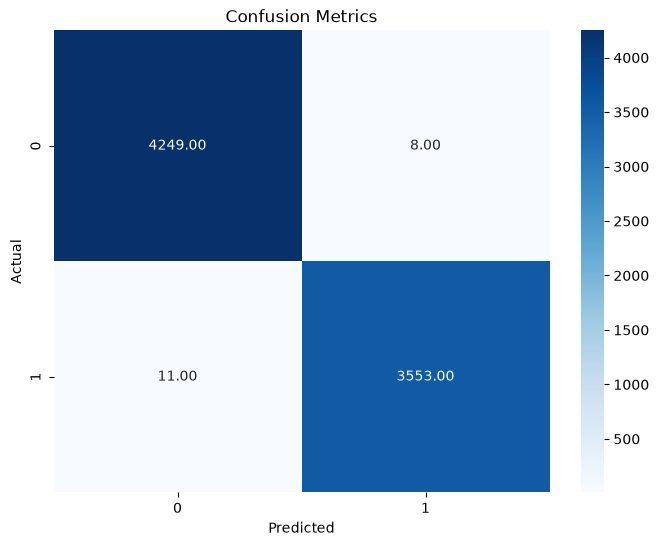

In [11]:
X = df.drop(columns=['label'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

vectorizer = TfidfVectorizer(max_features=10000)

vectorizer.fit(X_train['detail_text'])

X_train_vec = vectorizer.transform(X_train['detail_text'])
X_test_vec = vectorizer.transform(X_test['detail_text'])

mlflow.set_tracking_uri("http://127.0.0.1:5000/")

mlflow.set_experiment("XGBoost Model")

with mlflow.start_run():
    mlflow.set_tag("mlflow.runName","XGBoost_tfidf_vectorizer")
    mlflow.set_tag("experiment_type","baseline")
    mlflow.set_tag("model_type","XGBClassifier")

    mlflow.set_tag("description", "Baseline XGBoost model without any parameter.")

    mlflow.log_param("vectorizer_type","TfidfVectorizer")
    mlflow.log_param("vectorizer_max_feature",vectorizer.max_features)

    model = XGBClassifier(random_state=42)

    model.fit(X_train_vec,y_train)


    y_pred = model.predict(X_test_vec)

    accuracy = accuracy_score(y_test,y_pred)
    mlflow.log_metric("accuracy",accuracy)

    classific_report = classification_report(y_test,y_pred, output_dict=True)

    for label, metrics in classific_report.items():
        if isinstance(metrics, dict):
            for metric, value in metrics.items():
                mlflow.log_metric(f"{label}_{metric}",value)

    confusion_mat = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(confusion_mat, annot=True, fmt=".2f", cmap="Blues")
    plt.title("Confusion Metrics")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.savefig("../content/basemodel_confusion_metrics.png")
    mlflow.log_artifact("../content/basemodel_confusion_metrics.png")

    mlflow.sklearn.log_model(
        sk_model=model,
        name="XGBClassifier",
        serialization_format="pickle"    
    )

    
    mlflow.log_artifact("../content/True.csv")
    mlflow.log_artifact("../content/Fake.csv")

In [12]:
mlflow.sklearn.log_model(
    sk_model=model,
    name="XGBClassifier",
    registered_model_name="XGBClassifier",
    serialization_format="pickle"
)

2026/11/02 15:09:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/02 15:09:58 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'XGBClassifier'.
2026/11/02 15:09:59 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: XGBClassifier, version 1
Created version '1' of model 'XGBClassifier'.


In [18]:
X_test['label'] = y_test

In [22]:
fake = X_test[X_test['label'] == 0]
true = X_test[X_test['label'] == 1]

fake.to_csv("../content/Fake.csv",index=False)
true.to_csv("../content/True.csv",index=False)

In [24]:
df.columns.to_list()

['detail_text', 'label']